In [1]:
import os, sys
os.chdir(os.path.expanduser("~/ai_vision/subject9_machinevision"))

import cv2
import matplotlib.pyplot as plt

print("파이썬:", sys.executable)
print("현재 위치:", os.getcwd())
print("OpenCV:", cv2.__version__)

파이썬: /home/user1sim/ai_vision/subject9_machinevision/.venv/bin/python
현재 위치: /home/user1sim/ai_vision/subject9_machinevision
OpenCV: 5.0.0


In [3]:
import os
os.chdir(os.path.expanduser("~/ai_vision/subject9_machinevision"))
print(os.getcwd())

/home/user1sim/ai_vision/subject9_machinevision


In [5]:
%run src/12_clahe.py

문제 이미지 생성: samples/day02/low_contrast.jpg
저장: outputs/day02/clahe/clahe_clip_1.0.jpg
저장: outputs/day02/clahe/clahe_clip_2.0.jpg
저장: outputs/day02/clahe/clahe_clip_3.0.jpg
저장: outputs/day02/clahe/clahe_clip_4.0.jpg


In [7]:
# %load src/16_preprocess_compare.py

#전처리 전/후 종합 비교
from pathlib import Path

import cv2


# --------------------------------------------------
# 1. 사용할 이미지와 결과 저장 경로를 정한다.
#
#    reference_path
#    → 1일차에서 만든 병뚜껑 기준 ROI 이미지
#
#    low_contrast_path
#    → 대비를 낮춘 실습용 이미지
#
#    output_dir
#    → 전처리 비교 결과를 저장할 폴더
# --------------------------------------------------

reference_path = Path(
    "samples/day02/cap_on_reference.jpg"
)

low_contrast_path = Path(
    "samples/day02/low_contrast.jpg"
)

output_dir = Path(
    "outputs/day02/compare"
)


# --------------------------------------------------
# 2. 결과 이미지를 저장할 폴더를 생성한다.
#
#    폴더가 없다면 새로 만든다.
#    이미 존재한다면 그대로 사용한다.
# --------------------------------------------------

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# --------------------------------------------------
# 3. 저대비 이미지 low_contrast.jpg를 읽는다.
#
#    앞의 CLAHE 실습에서 만든 이미지를 재사용한다.
# --------------------------------------------------

image = cv2.imread(
    str(low_contrast_path)
)


# --------------------------------------------------
# 4. 저대비 이미지를 정상적으로 읽었는지 확인한다.
#
#    image가 None이면 5~6번을 실행한다.
#    정상적으로 읽었다면 5~6번을 건너뛴다.
# --------------------------------------------------

if image is None:

    print(
        "low_contrast.jpg가 없어 "
        "기준 이미지에서 생성합니다."
    )


    # --------------------------------------------------
    # 5. 병뚜껑 기준 ROI 이미지를 읽고 확인한다.
    #
    #    저대비 이미지를 다시 만들기 위한 원본이다.
    #    읽지 못했다면 오류를 발생시킨다.
    # --------------------------------------------------

    reference = cv2.imread(
        str(reference_path)
    )

    if reference is None:
        raise FileNotFoundError(
            f"기준 이미지를 읽지 못했습니다: "
            f"{reference_path}"
        )


    # --------------------------------------------------
    # 6. 기준 이미지의 Contrast를 낮추고 저장한다.
    #
    #    alpha=0.35 → 픽셀값의 차이를 줄인다.
    #    beta=80    → 픽셀값에 80을 더한다.
    #
    #    결과를 low_contrast.jpg로 저장한다.
    # --------------------------------------------------

    image = cv2.convertScaleAbs(
        reference,
        alpha=0.35,
        beta=80,
    )

    cv2.imwrite(
        str(low_contrast_path),
        image,
    )

    print(
        "문제 이미지 생성:",
        low_contrast_path,
    )


# --------------------------------------------------
# 7. 저대비 이미지를 Gray로 변환한다.
#
#    BGR → Gray
#
#    병뚜껑과 배경의 밝기 차이를 이용하여
#    다음 이진화 실습을 진행한다.
# --------------------------------------------------

gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY,
)


# --------------------------------------------------
# 8. 전처리 없이 Otsu 이진화를 적용한다.
#
#    Gray 이미지에 별도의 개선 처리를 하지 않고
#    Otsu를 바로 적용한다.
#
#    THRESH_BINARY_INV:
#    → 어두운 병뚜껑을 흰색 객체로 표현
#
#    original_value
#    → Otsu가 자동으로 선택한 임계값
#
#    original_otsu
#    → 이진화 결과 이미지
# --------------------------------------------------

original_value, original_otsu = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY_INV
    + cv2.THRESH_OTSU,
)


# --------------------------------------------------
# 9. 같은 Gray 이미지에 Gaussian Blur를 적용한다.
#
#    Kernel = 5×5
#
#    주변 픽셀의 가중 평균을 이용해
#    Noise를 부드럽게 줄인다.
#
#    결과를 gaussian 변수에 저장한다.
# --------------------------------------------------

gaussian = cv2.GaussianBlur(
    gray,
    (5, 5),
    0,
)


# --------------------------------------------------
# 10. Gaussian Blur 결과에 Otsu를 적용한다.
#
#     Gaussian으로 처리한 이미지를 이진화한다.
#
#     gaussian_value
#     → 자동 계산된 임계값
#
#     gaussian_otsu
#     → 이진화 결과 이미지
# --------------------------------------------------

gaussian_value, gaussian_otsu = cv2.threshold(
    gaussian,
    0,
    255,
    cv2.THRESH_BINARY_INV
    + cv2.THRESH_OTSU,
)


# --------------------------------------------------
# 11. CLAHE 객체를 생성한다.
#
#     clipLimit=2.0
#     → 지역 대비 향상 강도 설정
#
#     tileGridSize=(8, 8)
#     → 이미지를 가로 8개, 세로 8개 구역으로 나눔
#
#     CLAHE는 지역별 Contrast를 개선하는 방법이다.
# --------------------------------------------------

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8),
)


# --------------------------------------------------
# 12. 같은 Gray 이미지에 CLAHE를 적용한다.
#
#     병뚜껑과 주변 배경의 지역적인
#     밝기 차이를 개선한다.
#
#     결과를 clahe_image에 저장한다.
# --------------------------------------------------

clahe_image = clahe.apply(
    gray
)


# --------------------------------------------------
# 13. CLAHE 결과에 Otsu 이진화를 적용한다.
#
#     CLAHE로 개선한 이미지에서
#     병뚜껑과 배경을 분리한다.
#
#     clahe_value
#     → 자동 계산된 임계값
#
#     clahe_otsu
#     → 이진화 결과 이미지
# --------------------------------------------------

clahe_value, clahe_otsu = cv2.threshold(
    clahe_image,
    0,
    255,
    cv2.THRESH_BINARY_INV
    + cv2.THRESH_OTSU,
)


# --------------------------------------------------
# 14. 세 가지 Otsu 임계값을 출력한다.
#
#     Original + Otsu
#     Gaussian + Otsu
#     CLAHE + Otsu
#
#     입력 이미지가 다르므로
#     Otsu가 선택한 임계값도 달라질 수 있다.
# --------------------------------------------------

print(
    "Original Otsu:",
    original_value,
)

print(
    "Gaussian Otsu:",
    gaussian_value,
)

print(
    "CLAHE Otsu:",
    clahe_value,
)


# --------------------------------------------------
# 15. 비교 화면에 사용할 이미지 크기를 정한다.
#
#     가로 = 400px
#     세로 = 300px
#
#     네 장의 이미지를 같은 크기로 표시한다.
# --------------------------------------------------

view_size = (
    400,
    300,
)


# --------------------------------------------------
# 16. 비교 화면을 만드는 make_view() 함수를 정의한다.
#
#     source    → 표시할 이미지
#     title     → 이미지 위에 표시할 제목
#     is_binary → 이진화 이미지 여부
#
#     함수 내부 처리:
#
#     ① 이미지에 맞는 크기 변경 방법을 선택한다.
#     ② 이미지를 400×300으로 변경한다.
#     ③ Gray 이미지를 화면용 BGR로 변환한다.
#     ④ 이미지 위쪽에 검정색 제목 영역을 만든다.
#     ⑤ 제목을 흰색 글자로 표시한다.
#     ⑥ 완성된 화면 이미지를 반환한다.
#
#     함수는 여기서 정의만 하며,
#     실제 실행은 17~18번에서 호출할 때 이루어진다.
# --------------------------------------------------

def make_view(
    source,
    title,
    is_binary=False,
):

    # 이진화 이미지는 픽셀값이 섞이지 않도록
    # 가장 가까운 픽셀을 사용하는 방법으로 변경
    if is_binary:
        interpolation = cv2.INTER_NEAREST
    else:
        interpolation = cv2.INTER_AREA

    # 비교 화면 크기로 변경
    resized = cv2.resize(
        source,
        view_size,
        interpolation=interpolation,
    )

    # Gray 이미지라면 화면용 BGR로 변환
    if len(resized.shape) == 2:
        canvas = cv2.cvtColor(
            resized,
            cv2.COLOR_GRAY2BGR,
        )
    else:
        canvas = resized.copy()

    # 이미지 상단에 제목 영역 생성
    cv2.rectangle(
        canvas,
        (0, 0),
        (view_size[0], 40),
        (0, 0, 0),
        -1,
    )

    # 제목 표시
    cv2.putText(
        canvas,
        title,
        (10, 27),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 255, 255),
        2,
    )

    return canvas


# --------------------------------------------------
# 17. 비교 화면의 위쪽 두 이미지를 만든다.
#
#     왼쪽:
#     Low Contrast Gray
#     → 저대비 Gray 이미지
#
#     오른쪽:
#     Original + Otsu
#     → 별도 전처리 없이 Otsu 적용
#
#     cv2.hconcat()
#     → 이미지를 가로 방향으로 연결한다.
# --------------------------------------------------

top = cv2.hconcat(
    [
        make_view(
            gray,
            "Low Contrast Gray",
        ),
        make_view(
            original_otsu,
            "Original + Otsu",
            is_binary=True,
        ),
    ]
)


# --------------------------------------------------
# 18. 비교 화면의 아래쪽 두 이미지를 만든다.
#
#     왼쪽:
#     Gaussian + Otsu
#
#     오른쪽:
#     CLAHE + Otsu
#
#     두 이미지를 가로로 연결한다.
# --------------------------------------------------

bottom = cv2.hconcat(
    [
        make_view(
            gaussian_otsu,
            "Gaussian + Otsu",
            is_binary=True,
        ),
        make_view(
            clahe_otsu,
            "CLAHE + Otsu",
            is_binary=True,
        ),
    ]
)


# --------------------------------------------------
# 19. 위쪽과 아래쪽 이미지를 세로로 연결한다.
#
#     cv2.vconcat()
#     → 이미지를 세로 방향으로 연결한다.
#
#     최종 2×2 비교 화면을 만든다.
#
#     ┌───────────────────┬───────────────────┐
#     │ Low Contrast Gray │ Original + Otsu   │
#     ├───────────────────┼───────────────────┤
#     │ Gaussian + Otsu   │ CLAHE + Otsu      │
#     └───────────────────┴───────────────────┘
# --------------------------------------------------

compare = cv2.vconcat(
    [
        top,
        bottom,
    ]
)


# --------------------------------------------------
# 20. 최종 비교 이미지를 저장하고 경로를 출력한다.
#
#     저장 파일:
#     outputs/day02/compare/preprocess_compare.png
#
#     저장한 이미지를 직접 열어
#     병뚜껑과 배경의 분리 결과를 비교한다.
# --------------------------------------------------

output_path = (
    output_dir
    / "preprocess_compare.png"
)

cv2.imwrite(
    str(output_path),
    compare,
)

print(
    "저장:",
    output_path,
)



import matplotlib.pyplot as plt

files = ["samples/day02/low_contrast.jpg",
         "outputs/day02/clahe/clahe_clip_1.0.jpg",
         "outputs/day02/clahe/clahe_clip_2.0.jpg",
         "outputs/day02/clahe/clahe_clip_3.0.jpg",
         "outputs/day02/clahe/clahe_clip_4.0.jpg"]
titles = ["low_contrast", "clip 1.0", "clip 2.0", "clip 3.0", "clip 4.0"]

plt.figure(figsize=(16, 4))
for i, (f, t) in enumerate(zip(files, titles)):
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(t); plt.axis("off")
plt.show()

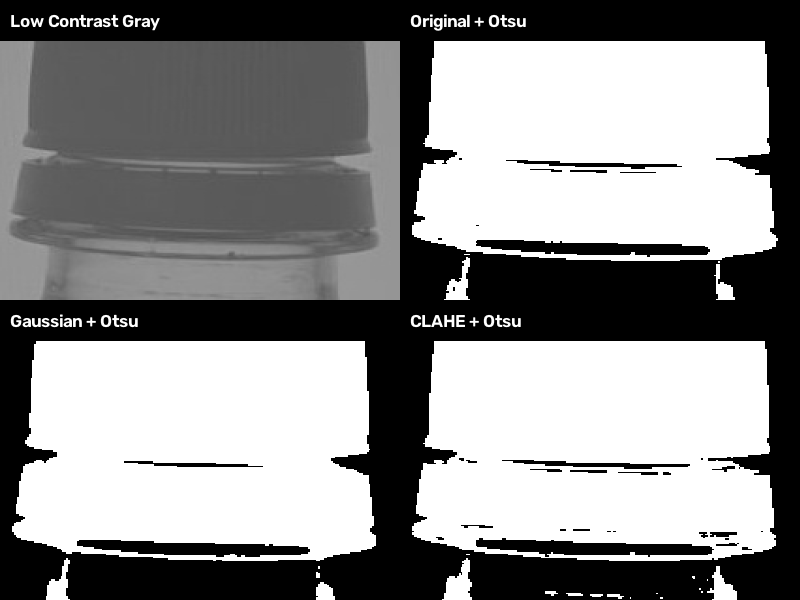

In [8]:
from IPython.display import Image
Image("outputs/day02/compare/preprocess_compare.png")

ON 크기: (198, 213)
OFF 크기: (198, 213)


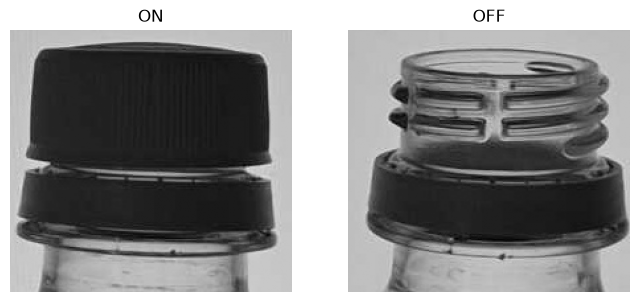

In [9]:
import cv2
import matplotlib.pyplot as plt

on  = cv2.imread("samples/day02/cap_on_reference.jpg",  cv2.IMREAD_GRAYSCALE)
off = cv2.imread("samples/day02/cap_off_reference.jpg", cv2.IMREAD_GRAYSCALE)

print("ON 크기:", on.shape)
print("OFF 크기:", off.shape)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(on, cmap="gray", vmin=0, vmax=255)
plt.title("ON")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(off, cmap="gray", vmin=0, vmax=255)
plt.title("OFF")
plt.axis("off")

plt.show()

In [12]:
# %load src/17_day02_challenge.py
# %% 0. 준비
import cv2
import matplotlib
#matplotlib.use("Agg")          # 창을 띄우지 않고 파일로만 저장하는 모드
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("outputs/day02/challenge")
OUT.mkdir(parents=True, exist_ok=True)

In [13]:
# %% 1. 두 이미지를 흑백으로 읽기
on  = cv2.imread("samples/day02/cap_on_reference.jpg",  cv2.IMREAD_GRAYSCALE)
off = cv2.imread("samples/day02/cap_off_reference.jpg", cv2.IMREAD_GRAYSCALE)

if on is None or off is None:
    raise FileNotFoundError("이미지를 못 찾았어요. 프로젝트 최상위 폴더에서 실행했는지 확인하세요.")

print("ON 크기:", on.shape)
print("OFF 크기:", off.shape)

ON 크기: (198, 213)
OFF 크기: (198, 213)


uint8 0 232


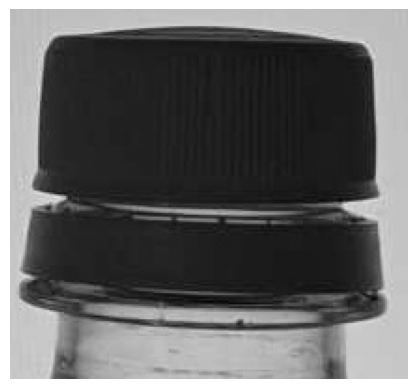

In [14]:
print(on.dtype, on.min(), on.max())
plt.imshow(on, cmap="gray", vmin=0, vmax=255); plt.axis("off"); plt.show()

In [15]:
# %% 2. 나란히 비교 이미지 저장
plt.figure(figsize=(8, 4))
for i, (img, title) in enumerate([(on, "ON"), (off, "OFF")]):
    plt.subplot(1, 2, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.savefig(OUT / "step1_gray.png")
plt.close()
print("저장:", OUT / "step1_gray.png")

저장: outputs/day02/challenge/step1_gray.png


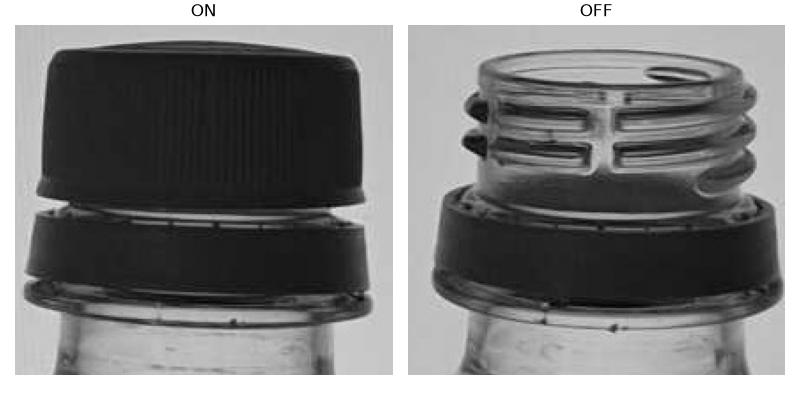

In [16]:
from IPython.display import Image
Image("outputs/day02/challenge/step1_gray.png")

원본 on        | 평균   89.4 | 표준편차  71.8 | min   0 | max 232
low_contrast | 평균  111.2 | 표준편차  25.2 | min  80 | max 162


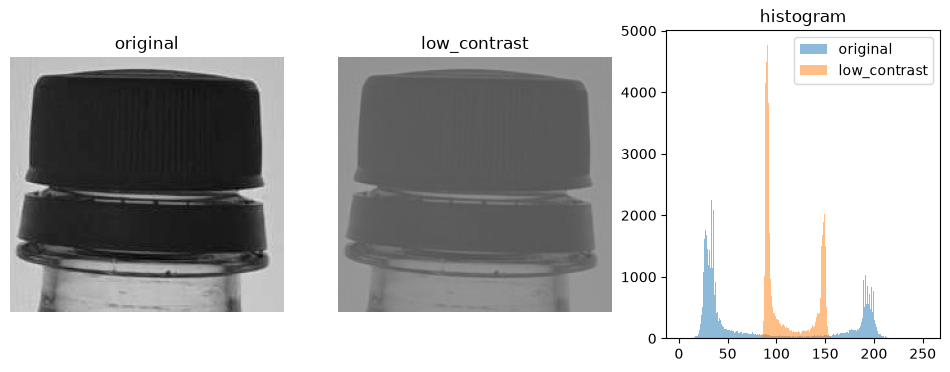

In [17]:
low = cv2.imread("samples/day02/low_contrast.jpg", cv2.IMREAD_GRAYSCALE)

for name, img in [("원본 on", on), ("low_contrast", low)]:
    print(f"{name:12} | 평균 {img.mean():6.1f} | 표준편차 {img.std():5.1f} | min {img.min():3} | max {img.max():3}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(on,  cmap="gray", vmin=0, vmax=255); plt.title("original"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(low, cmap="gray", vmin=0, vmax=255); plt.title("low_contrast"); plt.axis("off")
plt.subplot(1, 3, 3)
plt.hist(on.ravel(),  bins=256, range=(0, 255), alpha=0.5, label="original")
plt.hist(low.ravel(), bins=256, range=(0, 255), alpha=0.5, label="low_contrast")
plt.legend(); plt.title("histogram")
plt.show()

alpha = 3.11, beta = -248.8
원본 on        | 평균   89.4 | 표준편차  71.8 | min   0 | max 232
low_contrast | 평균  111.2 | 표준편차  25.2 | min  80 | max 162
보정 fixed     | 평균   97.0 | 표준편차  78.3 | min   0 | max 255


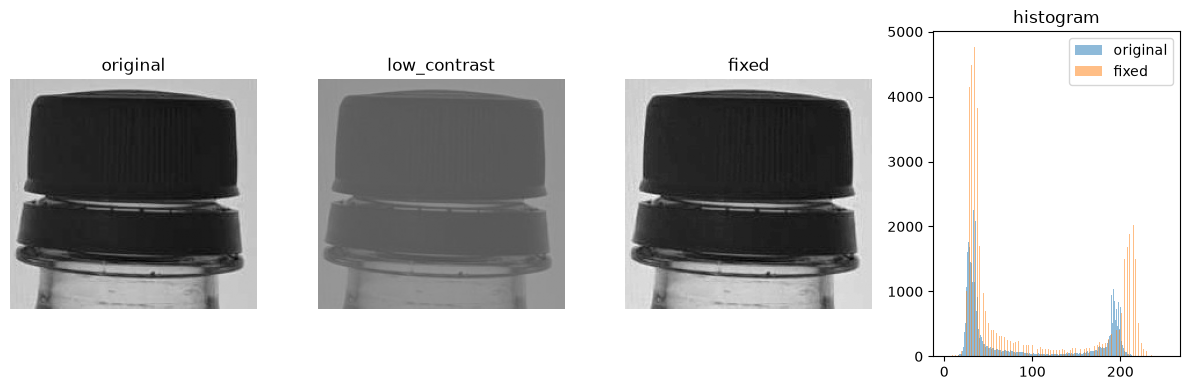

In [18]:
mn, mx = int(low.min()), int(low.max())
alpha = 255 / (mx - mn)
beta  = -mn * alpha
print(f"alpha = {alpha:.2f}, beta = {beta:.1f}")

fixed = cv2.convertScaleAbs(low, alpha=alpha, beta=beta)

for name, img in [("원본 on", on), ("low_contrast", low), ("보정 fixed", fixed)]:
    print(f"{name:12} | 평균 {img.mean():6.1f} | 표준편차 {img.std():5.1f} | min {img.min():3} | max {img.max():3}")

plt.figure(figsize=(12, 4))
for i, (img, t) in enumerate([(on, "original"), (low, "low_contrast"), (fixed, "fixed")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title(t); plt.axis("off")
plt.subplot(1, 4, 4)
plt.hist(on.ravel(),    bins=256, range=(0, 255), alpha=0.5, label="original")
plt.hist(fixed.ravel(), bins=256, range=(0, 255), alpha=0.5, label="fixed")
plt.legend(); plt.title("histogram")
plt.tight_layout(); plt.show()

## 2단계: 대비 보정 (Min-Max 정규화)

- low_contrast 범위: **80 ~ 162** (82칸만 사용)
- 공식: `alpha = 255 / (max - min)`, `beta = -min × alpha`
- 결과: 표준편차 25.2 → 78.3 으로 회복

> 결론: 두 산(뚜껑, 배경) 사이 거리가 다시 벌어짐

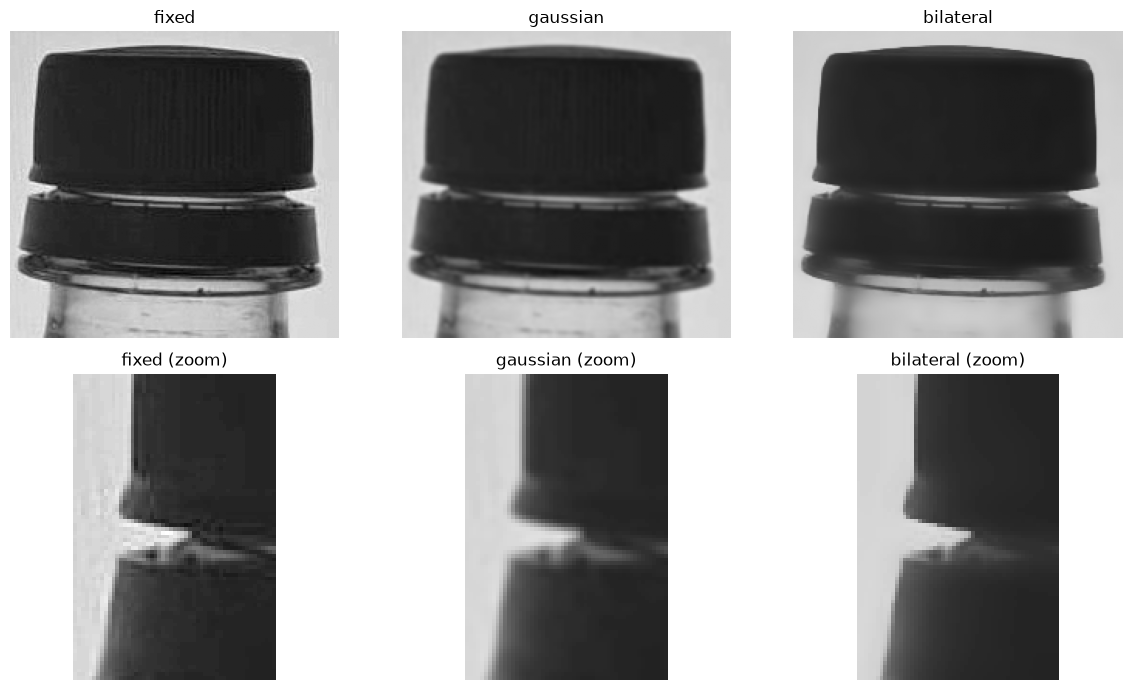

In [103]:
gauss = cv2.GaussianBlur(fixed, (5, 5), 0)
bil   = cv2.bilateralFilter(fixed, 15, 55, 5)

h, w = fixed.shape
crop = (slice(h//2 - 40, h//2 + 40), slice(0, w//4))

plt.figure(figsize=(12, 7))
for i, (img, t) in enumerate([(fixed, "fixed"), (gauss, "gaussian"), (bil, "bilateral")]):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title(t); plt.axis("off")
    plt.subplot(2, 3, i + 4)
    plt.imshow(img[crop], cmap="gray", vmin=0, vmax=255); plt.title(t + " (zoom)"); plt.axis("off")
plt.tight_layout(); plt.show()

## 3단계 결론: 노이즈 제거
- 선택: bilateralFilter(fixed, d=15, sigmaColor=55, sigmaSpace=5)
- 이유: gaussian보다 뚜껑 외곽선이 또렷함
- d=-1(지름 61)과 결과 비슷 → 작은 창 선택 (속도 유리)

fixed      | 임계값 118.0 | 정답과 일치 99.80%
gaussian   | 임계값 119.0 | 정답과 일치 98.95%
bilateral  | 임계값 120.0 | 정답과 일치 99.00%


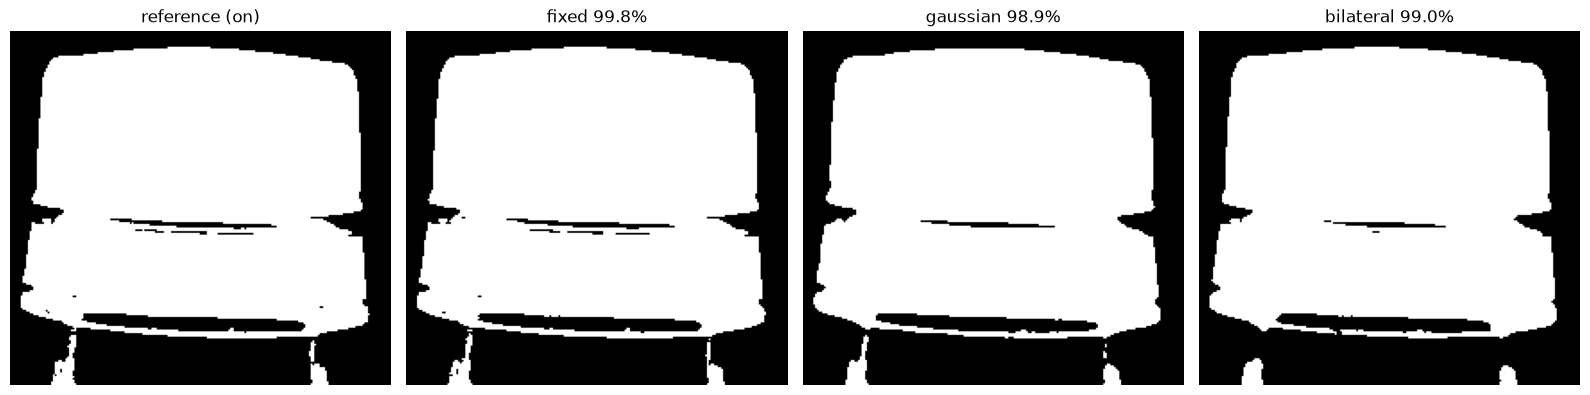

In [104]:
_, ref = cv2.threshold(on, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1); plt.imshow(ref, cmap="gray"); plt.title("reference (on)"); plt.axis("off")

for i, (img, name) in enumerate([(fixed, "fixed"), (gauss, "gaussian"), (bil, "bilateral")]):
    t, b = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    match = (b == ref).mean() * 100
    print(f"{name:10} | 임계값 {t:5.1f} | 정답과 일치 {match:5.2f}%")
    plt.subplot(1, 4, i + 2); plt.imshow(b, cmap="gray"); plt.title(f"{name} {match:.1f}%"); plt.axis("off")

plt.tight_layout(); plt.show()

임계값  60 | 흰 픽셀  56.2%
임계값  90 | 흰 픽셀  62.0%
임계값 118 | 흰 픽셀  64.9%
임계값 150 | 흰 픽셀  67.4%
임계값 180 | 흰 픽셀  70.9%


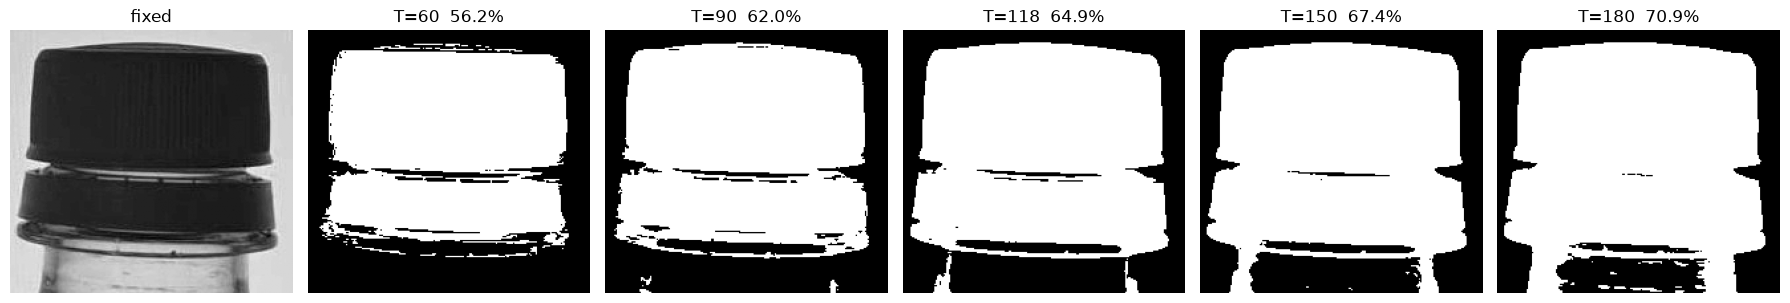

In [105]:
thresholds = [60, 90, 118, 150, 180]   # 118은 아까 Otsu가 고른 값

plt.figure(figsize=(18, 4))
plt.subplot(1, len(thresholds) + 1, 1)
plt.imshow(fixed, cmap="gray", vmin=0, vmax=255); plt.title("fixed"); plt.axis("off")

for i, t in enumerate(thresholds):
    _, b = cv2.threshold(fixed, t, 255, cv2.THRESH_BINARY_INV)
    ratio = cv2.countNonZero(b) / b.size * 100
    print(f"임계값 {t:3} | 흰 픽셀 {ratio:5.1f}%")
    plt.subplot(1, len(thresholds) + 1, i + 2)
    plt.imshow(b, cmap="gray"); plt.title(f"T={t}  {ratio:.1f}%"); plt.axis("off")

plt.tight_layout()
plt.savefig("outputs/day02/challenge/threshold_compare.png")
plt.show()

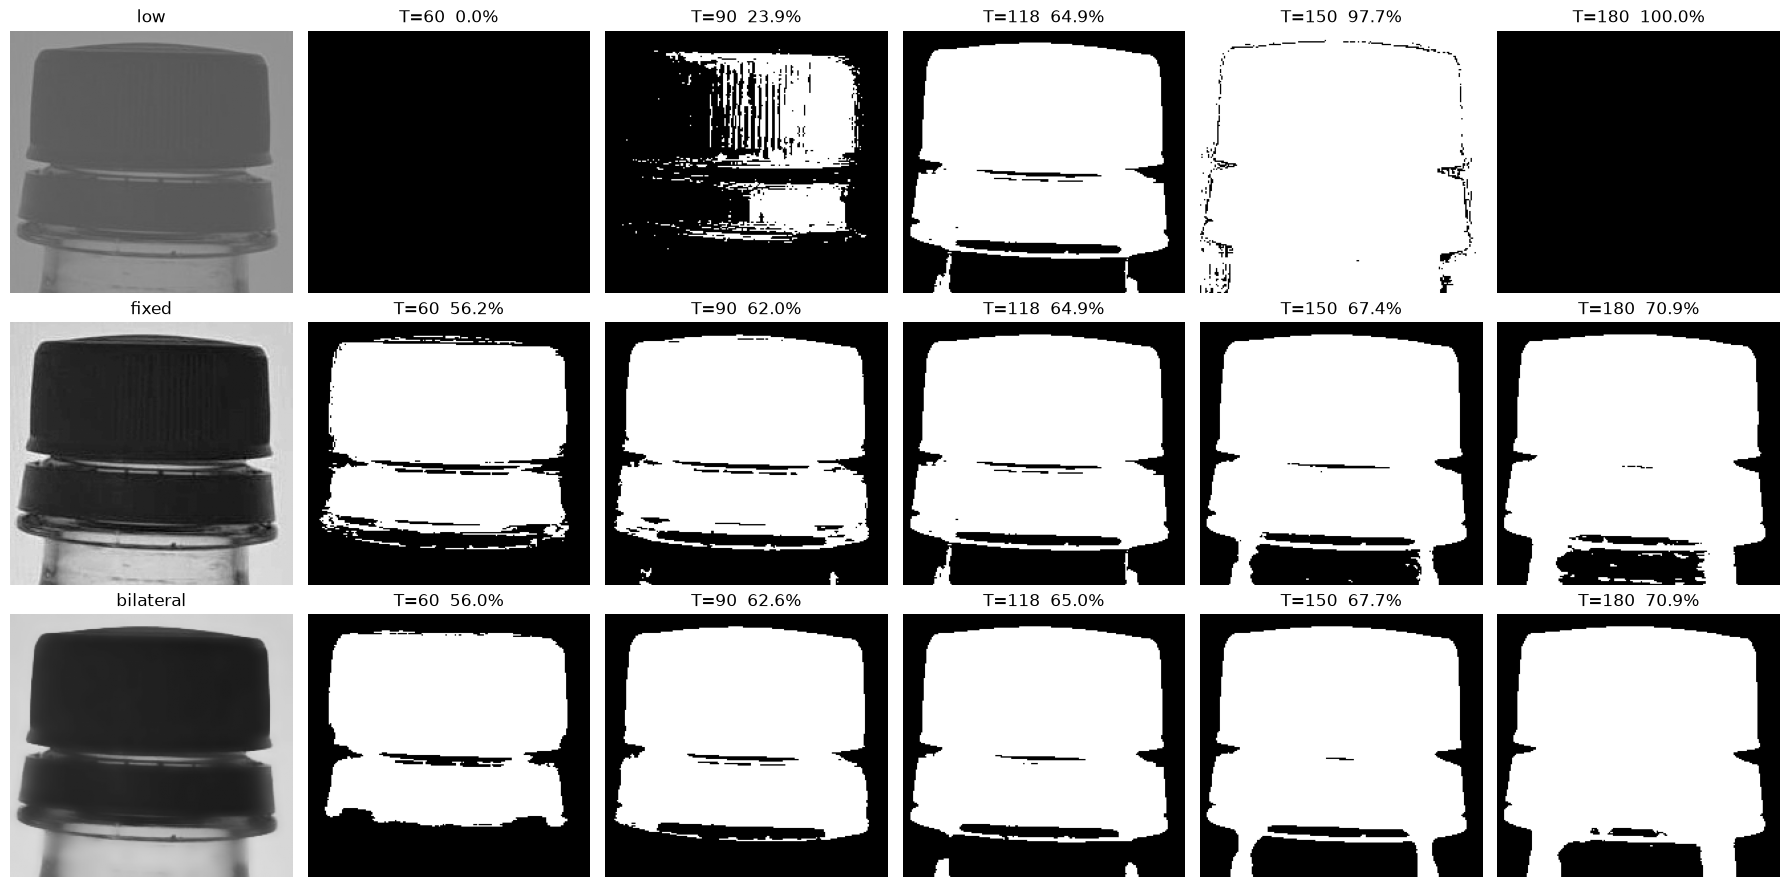

In [106]:
images = [("low", low), ("fixed", fixed), ("bilateral", bil)]
thresholds = [60, 90, 118, 150, 180]

rows, cols = len(images), len(thresholds) + 1
plt.figure(figsize=(3 * cols, 3 * rows))

for r, (name, img) in enumerate(images):
    # 각 줄의 맨 앞: 전처리된 이미지
    plt.subplot(rows, cols, r * cols + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title(name); plt.axis("off")

    # 나머지 칸: 임계값별 이진화 결과
    for c, t in enumerate(thresholds):
        _, b = cv2.threshold(img, t, 255, cv2.THRESH_BINARY_INV)
        ratio = cv2.countNonZero(b) / b.size * 100
        plt.subplot(rows, cols, r * cols + c + 2)
        plt.imshow(b, cmap="gray"); plt.title(f"T={t}  {ratio:.1f}%"); plt.axis("off")

plt.tight_layout()
plt.savefig("outputs/day02/challenge/threshold_grid.png")
plt.show()

## 5단계: 임계값 선택
- 후보: fixed + T=90 (흰 픽셀 62.0%)
- 이유: Otsu(118)보다 중간 밝기(유리·그림자)가 덜 섞여 뚜껑 경계가 깔끔
- 주의: 뚜껑 쪽 마진이 작음(약 59) → 조명이 밝아지면 위험할 수 있음

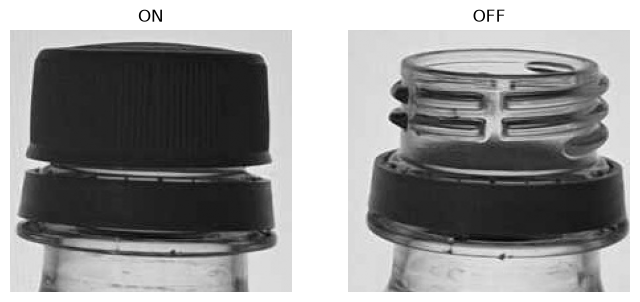

In [107]:
off = cv2.imread("samples/day02/cap_off_reference.jpg", cv2.IMREAD_GRAYSCALE)

on_n  = cv2.normalize(on,  None, 0, 255, cv2.NORM_MINMAX)
off_n = cv2.normalize(off, None, 0, 255, cv2.NORM_MINMAX)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(on_n,  cmap="gray", vmin=0, vmax=255); plt.title("ON");  plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(off_n, cmap="gray", vmin=0, vmax=255); plt.title("OFF"); plt.axis("off")
plt.show()

ON  | T=90      | 흰 픽셀  61.7%
ON  | Otsu=122  | 흰 픽셀  65.0%
OFF | T=90      | 흰 픽셀  36.1%
OFF | Otsu=133  | 흰 픽셀  48.7%


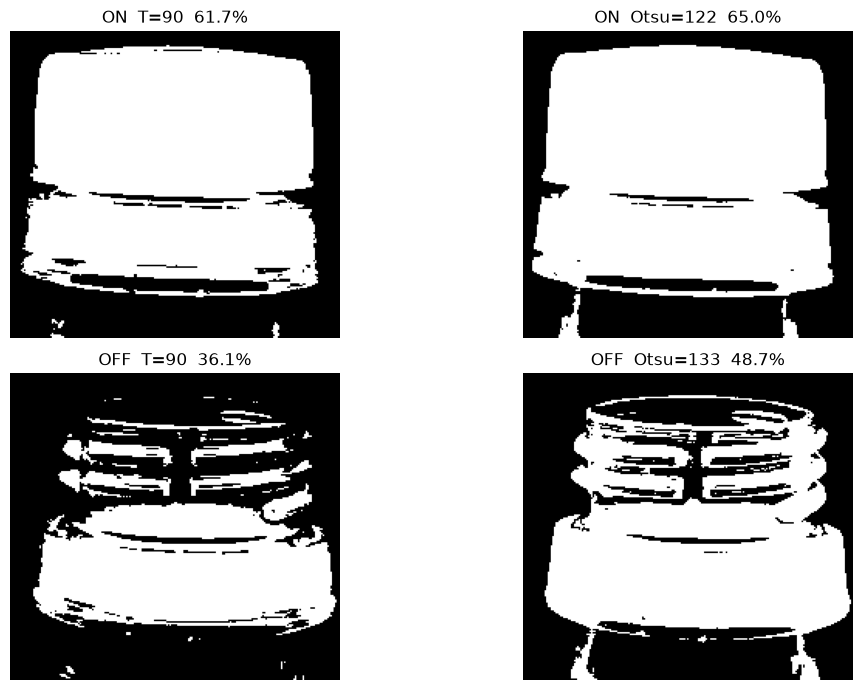

In [108]:
results = []
plt.figure(figsize=(12, 7))

for r, (name, img) in enumerate([("ON", on_n), ("OFF", off_n)]):
    _, b_fix = cv2.threshold(img, 90, 255, cv2.THRESH_BINARY_INV)
    t_otsu, b_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    for c, (method, b) in enumerate([("T=90", b_fix), (f"Otsu={t_otsu:.0f}", b_otsu)]):
        ratio = cv2.countNonZero(b) / b.size * 100
        print(f"{name:3} | {method:9} | 흰 픽셀 {ratio:5.1f}%")
        plt.subplot(2, 2, r * 2 + c + 1)
        plt.imshow(b, cmap="gray"); plt.title(f"{name}  {method}  {ratio:.1f}%"); plt.axis("off")

plt.tight_layout(); plt.show()